---
---

<h1><center><ins>Exercise Sheet 5</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp, cos

## Exercise 1 - Numerical derivative

**(A)** Compute the derivative of the following two functions:

$$ f_1(x) = x^2 + \cos(x) $$

$$ f_2(x) = \exp(x) - x^3 $$

in correspondence of at least $N = 50$ values $x_i$ ($i = 1, ..., N$) of the variable $x$ in the interval $[1,5]$. To do this, *write your own code to compute the derivatives numerically*.

**(B)** Compare the resulting values you get for the numerical derivatives with the corresponding analytic solutions. Calculate the value of the quantity $q$ for each function:

$$ q = \sum_{i=1}^N \frac{\left[d_i - f'(x_i) \right]}{f'(x_i)} $$

where $d_i$ are the values you obtained for the numerical derivatives for each of the $N$ abscissas, and $f'(x_i)$ are the analytical derivatives evaluated in points $x_i$. How does the value of $q$ change when changing the value of $h$ to compute the derivatives numerically? How do the values of $q$ compare for the two functions? Discuss your findings.

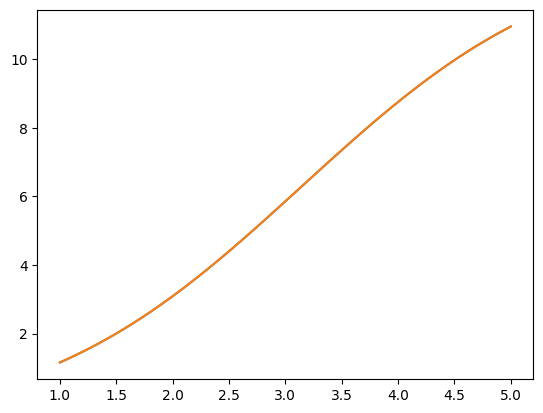

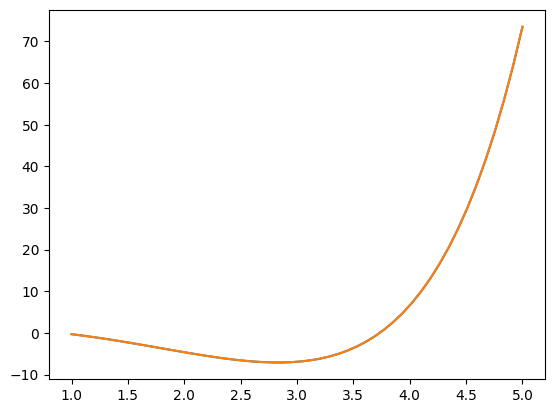

In [38]:
def derivative(x, f):
    h = (np.max(x) - np.min(x))/(len(x) - 1)
    return (f(x + h) - f(x - h))/ (2*h)
    
def f1(x):
    return x**2 + np.cos(x)

def f2(x):
    return np.exp(x) - x**3
    
def df1(x):
    return 2*x - np.sin(x)
def df2(x):
    return np.exp(x) - 3*x**2

    
x = np.linspace(1, 5, 50)
y1 = derivative(x, f1)
y2 = derivative(x, f2)

dy1 = df1(x)
dy2 = df2(x)
plt.plot(x, dy1)
plt.plot(x, y1)
plt.show()
plt.plot(x, dy2)
plt.plot(x, y2)
plt.show()

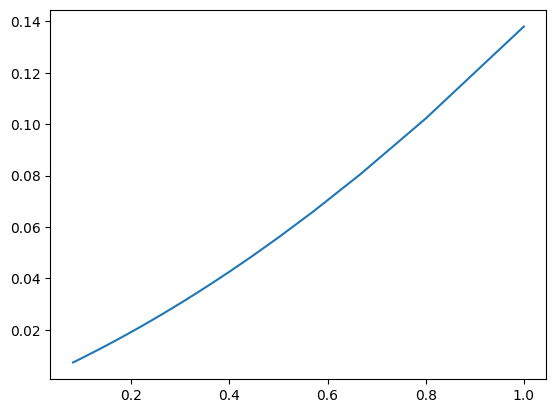

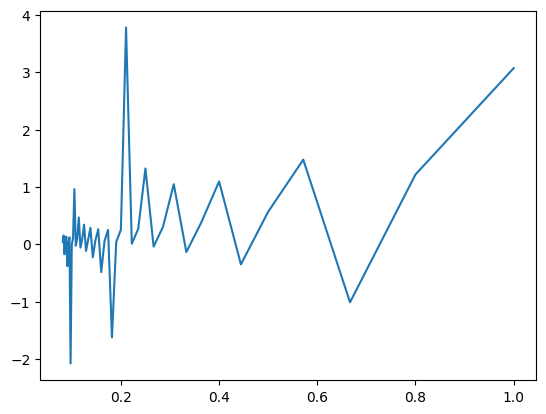

In [42]:
def df1(x):
    return 2*x - np.sin(x)
def df2(x):
    return np.exp(x) - 3*x**2


def q(x, f, df):
    di = derivative(x, f)
    d_f = df(x)
    return np.sum((di - d_f)/(d_f))

h_list = []
q1_list = []
q2_list = []
N = 5
while N <= 50:
    x = np.linspace(1, 5, N)
    q1 = q(x, f1, df1)
    q2 = q(x, f2, df2)
    h = (np.max(x) - np.min(x))/(len(x) - 1)
    h_list.append(h)
    q1_list.append(q1)
    q2_list.append(q2)
    N += 1
    
plt.plot(h_list, q1_list)
plt.show()
plt.plot(h_list, q2_list)
plt.show()

## Exercise 2 - Newton-Cotes formulas

In the file ```surface_luminosity.txt``` you will find the numerical function describing the surface luminosity $\Sigma$ of a globular star cluster as a function of the distance $R$ from its centre (projected on the plane of the sky). Compute the total luminosity $L$ of the system by performing the integral

$$ L = \int_0^{R_{\text{max}}} \Sigma(R) \, 2 \pi R \, dR $$

using the trapezoid rule and Simpson's rule, and compare the results you obtain. To do this, first choose one of these methods and implement **your own algorithm to compute the integral with it**; for the other method, use the corresponding built-in python function ```scipy.integrate.trapz``` or ```scipy.integrate.simps``` and familiarize on its usage.

In [ ]:
from scipy.integrate import simpson

"""path = "/home/vesna/5tes/Numerische_methoden/übungen/exercise 5/surface_luminosity.txt"

with open(path, "r") as f:
    contents = f.read()
#print(contents)"""
#R.append(f)
#surface_lum.append(f)

data = np.loadtxt("surface_luminosity.txt")
R, surface_lum = data.T

#print(data.shape)

integrand = 2 * np.pi * R * surface_lum

#trapezoid-rule implementation
L_trapezoid = 0.0

for i in range(len(R) - 1):
    width = R[i + 1] - R[i]
    average_height = (integrand[i] + integrand[i + 1]) / 2
    L_trapezoid += average_height * width

L_simpson = simpson(integrand, x=R)

print("Trapezoid:", L_trapezoid)
print("Simpson:", L_simpson)


(69, 2)
Trapezoid: 1285408.7095045173
Simpson: 1282549.6319938095


## Exercise 3 - Gaussian Quadrature

**(A)** Compute the following integral by using a 4-point Gaussian quadrature. 

$$ I = \int_{-1}^{1} \cos(x) dx $$

To do this, use the Legendre polynomial of degree 4:

$$ P_4(x) = \frac{1}{8}(35 x^4 - 30 x^2 +3) $$

At this link: https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature you can find the roots of Legendre polynomials and the necessary weights to solve the integral (i.e., you do not have to calculate them all from scratch!).

**(B)** Compare the result with the ones you obtain when using a Legendre polynomial of degree 3, 2, and 1, and comment your findings.

For n=4, the roots of P_4 are approximately $\pm0.339981$ and $\pm0.861136$. Their weights are approximately $0.652145$ for the inner roots and $0.347855$ for the outer roots. Therefore,

$I_4 \approx 2\left[0.652145\cos(0.339981)+0.347855\cos(0.861136)\right] \approx \boxed{1.682941689}.$
The factor of 2 combines each pair of symmetric roots, since cosine is even.



In [71]:
#Roots of n=4
#±0.339981
#±0.861136

from numpy.polynomial.legendre import leggauss

true_value = 2 * np.sin(1)  # Exact integral

for n in [4, 3, 2, 1]:
    roots, weights = leggauss(n)
    estimate = np.sum(weights * np.cos(roots))
    error = abs(estimate - true_value)
    print(f"{n} points: I ≈ {estimate:.9f}, absolute error = {error:.3g}")

print(f"Exact value: {true_value:.9f}")

4 points: I ≈ 1.682941689, absolute error = 2.81e-07
3 points: I ≈ 1.683003548, absolute error = 6.16e-05
2 points: I ≈ 1.675823655, absolute error = 0.00712
1 points: I ≈ 2.000000000, absolute error = 0.317
Exact value: 1.682941970


## Exercise 4 - Monte Carlo integration 

Consider the following integral:
$$ I = \int_0^1 \cos \left(\frac{\pi x}{2} \right) dx = \frac{2}{\pi} $$

**(A)** Compute the above integral and its variance by using the following Monte Carlo methods:

1. mean value

How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.



In [72]:
N = 10_000
rng = np.random.default_rng(42)

x = rng.uniform(0, 1, size=N)
f = np.cos(np.pi * x / 2)

I_est = np.mean(f)
variance_I = np.var(f, ddof=1) / N
sigma_I = np.sqrt(variance_I)

print("Monte Carlo estimate:", I_est)
print("Estimated variance of estimate:", variance_I)
print("Estimated uncertainty (sigma_I):", sigma_I)
print("Exact value:", 2 / np.pi)

Monte Carlo estimate: 0.63986433059349
Estimated variance of estimate: 9.417275149919602e-06
Estimated uncertainty (sigma_I): 0.0030687579164736345
Exact value: 0.6366197723675814


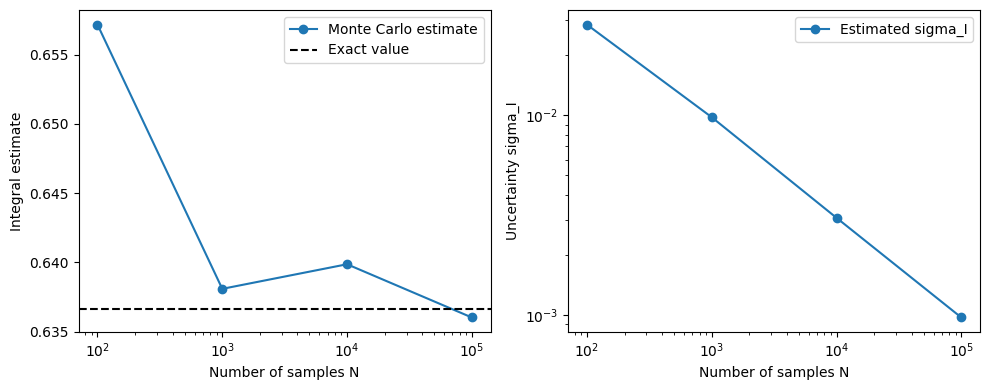

In [73]:
Ns = np.array([100, 1_000, 10_000, 100_000])
rng = np.random.default_rng(42)

x = rng.uniform(0, 1, size=Ns[-1])
f = np.cos(np.pi * x / 2)

estimates = []
variances = []
sigmas = []

for N in Ns:
    values = f[:N]
    estimates.append(np.mean(values))
    variance_I = np.var(values, ddof=1) / N
    variances.append(variance_I)
    sigmas.append(np.sqrt(variance_I))

I_exact = 2 / np.pi

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(Ns, estimates, "o-", label="Monte Carlo estimate")
axes[0].axhline(I_exact, color="black", linestyle="--", label="Exact value")
axes[0].set_xscale("log")
axes[0].set_xlabel("Number of samples N")
axes[0].set_ylabel("Integral estimate")
axes[0].legend()

axes[1].plot(Ns, sigmas, "o-", label="Estimated sigma_I")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of samples N")
axes[1].set_ylabel("Uncertainty sigma_I")
axes[1].legend()

plt.tight_layout()
plt.show()

## Exercise 5 - Monte Carlo integration continued (optional)

**(A)** Compute the above integral from Exercise 4 and its variance by using the other Monte Carlo methods covered in the lecture:

2. Importance sampling

Hint: for importance sampling, you can use the following weight function: 
$$w(x) = A \frac{1}{1+\left( \pi x/2 \right)^2}$$
where you can determine the normalization constant by imposing:
$$\int_0^1 w(x) dx = 1 = A \frac{2}{\pi} \arctan(\pi/2) \rightarrow A = \frac{\pi}{2 \arctan(\pi/2)}$$


How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.